# Part A- Question 4

In [305]:
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px
import os
from pprint import pprint
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
import warnings
from datetime import date
import statistics
from sklearn.model_selection import train_test_split
warnings.filterwarnings('ignore')

In [105]:
import kagglehub

## Loading Data
We will use kaggle hub to load the data.</br>
The kaggle hub downloads the file locally and we can use that file.

In [106]:
path = kagglehub.dataset_download("dansbecker/melbourne-housing-snapshot")

print("Path to dataset files:", path)

Path to dataset files: ~/.cache/kagglehub/datasets/dansbecker/melbourne-housing-snapshot/versions/5


In [107]:
os.chdir(path)
print("path changed to file path")
files=os.listdir()
print(files)
file=files[-1]
print("got file")
file=os.path.join(path,file)
print(file)

path changed to file path
['melb_data.csv']
got file
~/.cache/kagglehub/datasets/dansbecker/melbourne-housing-snapshot/versions/5/melb_data.csv


## Data Exploration

In [108]:
df_melb=pd.read_csv(file)

In [109]:
df_melb.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


##### List columns

In [110]:
cols=list(df_melb.columns)
pprint(cols)

['Suburb',
 'Address',
 'Rooms',
 'Type',
 'Price',
 'Method',
 'SellerG',
 'Date',
 'Distance',
 'Postcode',
 'Bedroom2',
 'Bathroom',
 'Car',
 'Landsize',
 'BuildingArea',
 'YearBuilt',
 'CouncilArea',
 'Lattitude',
 'Longtitude',
 'Regionname',
 'Propertycount']


In [111]:
print(df_melb.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  object 
 1   Address        13580 non-null  object 
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  object 
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  object 
 6   SellerG        13580 non-null  object 
 7   Date           13580 non-null  object 
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  object 
 17  Lattitude      13580 non-null  float64
 18  Longti

### Finding null values
Here we will find which columns have missing data present into it. </br>
We created a table with feature names and number of null values present in it.

In [112]:
null_vals=pd.DataFrame(df_melb.isnull().sum(),columns=['Null Count'],index=cols)
# null_vals.index.name='Feature Name'



In [113]:
null_vals

,Null Count
Suburb,0
Address,0
Rooms,0
Type,0
Price,0
Method,0
SellerG,0
Date,0
Distance,0
Postcode,0


In [114]:
df_melb.describe()

,Rooms,Price,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount
count,13580.000000,1.358000e+04,13580.000000,13580.000000,13580.000000,13580.000000,13518.000000,13580.000000,7130.000000,8205.000000,13580.000000,13580.000000,13580.000000
mean,2.937997,1.075684e+06,10.137776,3105.301915,2.914728,1.534242,1.610075,558.416127,151.967650,1964.684217,-37.809203,144.995216,7454.417378
std,0.955748,6.393107e+05,5.868725,90.676964,0.965921,0.691712,0.962634,3990.669241,541.014538,37.273762,0.079260,0.103916,4378.581772
min,1.000000,8.500000e+04,0.000000,3000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1196.000000,-38.182550,144.431810,249.000000
25%,2.000000,6.500000e+05,6.100000,3044.000000,2.000000,1.000000,1.000000,177.000000,93.000000,1940.000000,-37.856822,144.929600,4380.000000
50%,3.000000,9.030000e+05,9.200000,3084.000000,3.000000,1.000000,2.000000,440.000000,126.000000,1970.000000,-37.802355,145.000100,6555.000000
75%,3.000000,1.330000e+06,13.000000,3148.000000,3.000000,2.000000,2.000000,651.000000,174.000000,1999.000000,-37.756400,145.058305,10331.000000
max,10.000000,9.000000e+06,48.100000,3977.000000,20.000000,8.000000,10.000000,433014.000000,44515.000000,2018.000000,-37.408530,145.526350,21650.000000


### Fearture engineering, Handling null values and EDA
In this section we have :
1) Tried to do feature engineering by adding more columns that may be relevant to our problem statement.
2) Handled missing values.
3) Dropped columns that are not required.
4) Performed EDA where we came up with visualisation that can give more insights about the data.


In [115]:
#
df_melb['Date']=pd.to_datetime(df_melb['Date'],format="%d/%m/%Y")
df_melb['Year Sold']=df_melb['Date'].dt.year

In [116]:
df_melb.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount,Year Sold
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,2016-12-03,2.5,3067.0,...,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0,2016
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,2016-02-04,2.5,3067.0,...,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0,2016
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,2017-03-04,2.5,3067.0,...,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0,2017
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,2017-03-04,2.5,3067.0,...,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0,2017
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,2016-06-04,2.5,3067.0,...,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0,2016


In [117]:
#convert it into number
df_melb['Year Sold']=df_melb['Year Sold'].astype('Int64')


In [118]:
# first let's drop features that are not required
cols_to_drop=['Address','Lattitude','Longtitude','Postcode','Date']
df_melb.drop(columns=cols_to_drop,axis=0,inplace=True)


In [119]:
df_melb.head()

,Suburb,Rooms,Type,Price,Method,SellerG,Distance,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Regionname,Propertycount,Year Sold
0,Abbotsford,2,h,1480000.0,S,Biggin,2.5,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,Northern Metropolitan,4019.0,2016
1,Abbotsford,2,h,1035000.0,S,Biggin,2.5,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,Northern Metropolitan,4019.0,2016
2,Abbotsford,3,h,1465000.0,SP,Biggin,2.5,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,Northern Metropolitan,4019.0,2017
3,Abbotsford,3,h,850000.0,PI,Biggin,2.5,3.0,2.0,1.0,94.0,NaN,NaN,Yarra,Northern Metropolitan,4019.0,2017
4,Abbotsford,4,h,1600000.0,VB,Nelson,2.5,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,Northern Metropolitan,4019.0,2016


#### Handling missing values
To handle missing values, we will follow two approaches
1) Using imputation
2) Manual approach, where we will fill missing values accordingly(eg. mean, median etc)

##### Using Imputation 

In [120]:
#getting null cols
null_cols=[col for col in df_melb.columns if df_melb[col].isnull().any()]

In [121]:
null_cols

['Car', 'BuildingArea', 'YearBuilt', 'CouncilArea']

Now we have our columns with null values, we will extract these columns from our original data</br>
with numericals columns, impute the mising values and append thee rest of the data to get out cleaned dataset

In [122]:
df_imputed=df_melb[null_cols]

In [123]:
df_imputed.head(10)

,Car,BuildingArea,YearBuilt,CouncilArea
0,1.0,NaN,NaN,Yarra
1,0.0,79.0,1900.0,Yarra
2,0.0,150.0,1900.0,Yarra
3,1.0,NaN,NaN,Yarra
4,2.0,142.0,2014.0,Yarra
5,0.0,NaN,NaN,Yarra
6,0.0,210.0,1910.0,Yarra
7,2.0,107.0,1890.0,Yarra
8,1.0,NaN,NaN,Yarra
9,2.0,75.0,1900.0,Yarra


In [124]:
simple_imputer=SimpleImputer(strategy='most_frequent')
imputed_values=simple_imputer.fit_transform(df_imputed)

In [125]:
df_imputed=pd.DataFrame(imputed_values,columns=null_cols)

In [126]:
df_imputed.head(10)

,Car,BuildingArea,YearBuilt,CouncilArea
0,1.0,120.0,1970.0,Yarra
1,0.0,79.0,1900.0,Yarra
2,0.0,150.0,1900.0,Yarra
3,1.0,120.0,1970.0,Yarra
4,2.0,142.0,2014.0,Yarra
5,0.0,120.0,1970.0,Yarra
6,0.0,210.0,1910.0,Yarra
7,2.0,107.0,1890.0,Yarra
8,1.0,120.0,1970.0,Yarra
9,2.0,75.0,1900.0,Yarra


In [127]:
cols_to_add=[col for col in df_melb.columns.tolist() if col not in null_cols]

In [128]:
cols_to_add

['Suburb',
 'Rooms',
 'Type',
 'Price',
 'Method',
 'SellerG',
 'Distance',
 'Bedroom2',
 'Bathroom',
 'Landsize',
 'Regionname',
 'Propertycount',
 'Year Sold']

In [129]:
df_imputed=pd.merge(df_melb[cols_to_add],df_imputed,left_index=True,right_index=True,how='left')

In [130]:
df_imputed.head()

,Suburb,Rooms,Type,Price,Method,SellerG,Distance,Bedroom2,Bathroom,Landsize,Regionname,Propertycount,Year Sold,Car,BuildingArea,YearBuilt,CouncilArea
0,Abbotsford,2,h,1480000.0,S,Biggin,2.5,2.0,1.0,202.0,Northern Metropolitan,4019.0,2016,1.0,120.0,1970.0,Yarra
1,Abbotsford,2,h,1035000.0,S,Biggin,2.5,2.0,1.0,156.0,Northern Metropolitan,4019.0,2016,0.0,79.0,1900.0,Yarra
2,Abbotsford,3,h,1465000.0,SP,Biggin,2.5,3.0,2.0,134.0,Northern Metropolitan,4019.0,2017,0.0,150.0,1900.0,Yarra
3,Abbotsford,3,h,850000.0,PI,Biggin,2.5,3.0,2.0,94.0,Northern Metropolitan,4019.0,2017,1.0,120.0,1970.0,Yarra
4,Abbotsford,4,h,1600000.0,VB,Nelson,2.5,3.0,1.0,120.0,Northern Metropolitan,4019.0,2016,2.0,142.0,2014.0,Yarra


In [131]:
curr_year=date.today().year
df_imputed['Years Old']=curr_year-df_imputed['YearBuilt']

In [132]:
df_imputed.head()


,Suburb,Rooms,Type,Price,Method,SellerG,Distance,Bedroom2,Bathroom,Landsize,Regionname,Propertycount,Year Sold,Car,BuildingArea,YearBuilt,CouncilArea,Years Old
0,Abbotsford,2,h,1480000.0,S,Biggin,2.5,2.0,1.0,202.0,Northern Metropolitan,4019.0,2016,1.0,120.0,1970.0,Yarra,55.0
1,Abbotsford,2,h,1035000.0,S,Biggin,2.5,2.0,1.0,156.0,Northern Metropolitan,4019.0,2016,0.0,79.0,1900.0,Yarra,125.0
2,Abbotsford,3,h,1465000.0,SP,Biggin,2.5,3.0,2.0,134.0,Northern Metropolitan,4019.0,2017,0.0,150.0,1900.0,Yarra,125.0
3,Abbotsford,3,h,850000.0,PI,Biggin,2.5,3.0,2.0,94.0,Northern Metropolitan,4019.0,2017,1.0,120.0,1970.0,Yarra,55.0
4,Abbotsford,4,h,1600000.0,VB,Nelson,2.5,3.0,1.0,120.0,Northern Metropolitan,4019.0,2016,2.0,142.0,2014.0,Yarra,11.0


##### Manual Approch
In manual approach we will try different methods like grouping by suburb,regionname and then fill up missing values

In [133]:
#year built has null vals
def fill_null(col1,col2):
    d={}
    for val1,val2 in zip(col1,col2):
        if val1 not in  d:
            d[val1]=[val2]
        else:
            d[val1].append(val2)

    return d
        


In [134]:
suburb_built=fill_null(df_melb['Suburb'].dropna(),df_melb['YearBuilt'].dropna())

In [135]:
region_bult=fill_null(df_melb['Regionname'].dropna(),df_melb['YearBuilt'].dropna())

In [136]:
#function to find median
def find_median(dictionary):
    medians={}
    for key in dictionary.keys():
        #print(f"{key} : {dictionary[key]}")
        med=statistics.median(dictionary[key])
        #print(med)
        medians[key]=med
    return medians

In [137]:
suburb_median=find_median(suburb_built)


In [138]:
print("Median of year built according to suburb: ",end="\n")
pprint(suburb_median)


Median of year built according to suburb: 
{'Abbotsford': 1967.5,
 'Aberfeldie': 1980.0,
 'Airport West': 1905.0,
 'Albert Park': 1970.0,
 'Albion': 1984.5,
 'Alphington': 1964.0,
 'Altona': 1935.0,
 'Altona North': 1944.5,
 'Armadale': 1954.0,
 'Ascot Vale': 1970.0,
 'Ashburton': 1960.0,
 'Ashwood': 1960.5,
 'Avondale Heights': 1960.0,
 'Balaclava': 1980.0,
 'Balwyn': 1970.0,
 'Balwyn North': 1970.0,
 'Bellfield': 1972.0,
 'Bentleigh': 1960.0,
 'Bentleigh East': 1960.0,
 'Box Hill': 1963.0,
 'Braybrook': 1960.0,
 'Brighton': 1970.0,
 'Brighton East': 1960.0,
 'Brooklyn': 1980.0,
 'Brunswick': 1969.5,
 'Brunswick East': 1970.0,
 'Brunswick West': 1965.0,
 'Bulleen': 1960.0,
 'Burnley': 2009.0,
 'Burwood': 1960.0,
 'Camberwell': 1970.0,
 'Campbellfield': 2010.0,
 'Canterbury': 1962.5,
 'Carlton': 1970.0,
 'Carlton North': 1955.0,
 'Carnegie': 1960.0,
 'Caulfield': 1980.0,
 'Caulfield East': 1996.0,
 'Caulfield North': 1940.0,
 'Caulfield South': 1960.0,
 'Chadstone': 1960.0,
 'Clifton H

In [139]:
region_median=find_median(region_bult)
print("Median of year built according to suburb: ",end="\n")
pprint(region_median)


Median of year built according to suburb: 
{'Eastern Metropolitan': 1965.0,
 'Northern Metropolitan': 1970.0,
 'South-Eastern Metropolitan': 1955.5,
 'Southern Metropolitan': 1970.0,
 'Western Metropolitan': 1970.0}


Now since we have got our median values for year built for each suburb, let's fill out missing data

In [140]:
def fill_null_values(row,values,col_to_fil,ref_col):
    if pd.isna(row[col_to_fil]):
        return values.get(row[ref_col],row[col_to_fil])
    else:
        return row[col_to_fil]
    

In [141]:
df_melb['YearBuilt']=df_melb.apply(lambda row: fill_null_values(row,suburb_median,'YearBuilt','Suburb'),axis=1)

In [176]:
df_melb['YearBuilt']=df_melb.apply(lambda row: fill_null_values(row,region_median,'YearBuilt','Regionname'),axis=1)

In [142]:
df_melb.head()

,Suburb,Rooms,Type,Price,Method,SellerG,Distance,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Regionname,Propertycount,Year Sold
0,Abbotsford,2,h,1480000.0,S,Biggin,2.5,2.0,1.0,1.0,202.0,NaN,1967.5,Yarra,Northern Metropolitan,4019.0,2016
1,Abbotsford,2,h,1035000.0,S,Biggin,2.5,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,Northern Metropolitan,4019.0,2016
2,Abbotsford,3,h,1465000.0,SP,Biggin,2.5,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,Northern Metropolitan,4019.0,2017
3,Abbotsford,3,h,850000.0,PI,Biggin,2.5,3.0,2.0,1.0,94.0,NaN,1967.5,Yarra,Northern Metropolitan,4019.0,2017
4,Abbotsford,4,h,1600000.0,VB,Nelson,2.5,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,Northern Metropolitan,4019.0,2016


Simillarly we will fill columns like
1) Building Area
2) Car

In [144]:
building_area_suburb=fill_null(df_melb['Suburb'].dropna(),df_melb['BuildingArea'].dropna())
buillding_area_region=fill_null(df_melb['Regionname'].dropna(),df_melb['BuildingArea'].dropna())

In [145]:
pprint(building_area_suburb)

{'Abbotsford': [79.0,
                150.0,
                142.0,
                210.0,
                107.0,
                75.0,
                190.0,
                94.0,
                97.0,
                110.0,
                105.0,
                73.0,
                135.0,
                27.0,
                60.0,
                135.0,
                85.0,
                174.0,
                50.0,
                128.0,
                18.0,
                124.0,
                50.0,
                91.0,
                128.0,
                82.0,
                81.0,
                225.0,
                145.0,
                145.0,
                84.0,
                134.0,
                116.0,
                86.0,
                127.0,
                186.0,
                90.0,
                73.0],
 'Aberfeldie': [244.0,
                230.0,
                61.0,
                100.0,
                145.0,
                86.0,
       

In [146]:
pprint(buillding_area_region)

{'Eastern Metropolitan': [130.0,
                          170.0,
                          237.0,
                          34.0,
                          170.0,
                          56.0,
                          133.0,
                          96.0,
                          86.0,
                          201.0,
                          223.0,
                          102.0,
                          200.0,
                          106.0,
                          90.0,
                          71.0,
                          73.0,
                          250.0,
                          82.0,
                          110.0,
                          64.0,
                          80.0,
                          182.0,
                          2.0,
                          53.0,
                          166.0,
                          167.0,
                          120.0,
                          72.0,
                          221.0,
                        

In [147]:
suburb_area_median=find_median(building_area_suburb)
region_area_median=find_median(buillding_area_region)

In [148]:
print(f"median of building area according to suburb : {suburb_area_median}",end="\n\n")
print(f"median of building area according to region : {region_area_median}",end="\n\n")


median of building area according to suburb : {'Abbotsford': 106.0, 'Airport West': 128.0, 'Albert Park': 119.0, 'Alphington': 116.0, 'Altona': 108.0, 'Altona North': 148.0, 'Armadale': 149.0, 'Ascot Vale': 168.0, 'Ashburton': 176.0, 'Ashwood': 160.0, 'Avondale Heights': 140.5, 'Balaclava': 165.0, 'Balwyn': 135.0, 'Balwyn North': 195.0, 'Bentleigh': 105.0, 'Bentleigh East': 140.0, 'Box Hill': 106.0, 'Braybrook': 100.0, 'Brighton': 117.0, 'Brighton East': 131.0, 'Brunswick': 110.0, 'Brunswick West': 107.0, 'Bulleen': 110.0, 'Burwood': 87.0, 'Camberwell': 140.0, 'Canterbury': 128.5, 'Carlton North': 129.0, 'Carnegie': 137.5, 'Caulfield': 82.0, 'Caulfield North': 88.0, 'Caulfield South': 112.5, 'Chadstone': 93.5, 'Clifton Hill': 93.5, 'Coburg': 127.0, 'Coburg North': 175.0, 'Collingwood': 156.5, 'Doncaster': 128.0, 'Eaglemont': 114.0, 'Elsternwick': 128.0, 'Elwood': 115.0, 'Essendon': 141.0, 'Essendon North': 69.5, 'Fairfield': 96.0, 'Fitzroy': 107.0, 'Fitzroy North': 130.0, 'Flemington':

In [149]:
#now fill these missing values
df_melb['BuildingArea']=df_melb.apply(lambda row: fill_null_values(row,suburb_area_median,'BuildingArea','Suburb'),axis=1)

In [174]:
df_melb['BuildingArea']=df_melb.apply(lambda row: fill_null_values(row,region_area_median,'BuildingArea','Regionname'),axis=1)

In [152]:
# same for car park 
car_suburb=fill_null(df_melb['Suburb'].dropna(),df_melb['Car'].dropna())
car_region=fill_null(df_melb['Regionname'].dropna(),df_melb['Car'].dropna())

car_suburb_median=find_median(car_suburb)
car_region_median=find_median(car_region)

In [153]:
print(f"median of car according to suburb : {car_suburb_median}",end="\n\n")
print(f"median of car according to region : {car_region_median}",end="\n\n")

median of car according to suburb : {'Abbotsford': 1.0, 'Airport West': 1.0, 'Albert Park': 1.0, 'Alphington': 2.0, 'Altona': 2.0, 'Altona North': 2.0, 'Armadale': 1.0, 'Ascot Vale': 1.0, 'Ashburton': 2.0, 'Ashwood': 2.0, 'Avondale Heights': 2.0, 'Balaclava': 1.0, 'Balwyn': 2.0, 'Balwyn North': 2.0, 'Bentleigh': 2.0, 'Bentleigh East': 2.0, 'Box Hill': 1.0, 'Braybrook': 1.5, 'Brighton': 2.0, 'Brighton East': 2.0, 'Brunswick': 1.0, 'Brunswick West': 1.0, 'Bulleen': 2.0, 'Burwood': 2.0, 'Camberwell': 2.0, 'Canterbury': 2.0, 'Carlton North': 1.0, 'Carnegie': 1.0, 'Caulfield': 1.0, 'Caulfield North': 1.0, 'Caulfield South': 1.0, 'Chadstone': 2.0, 'Clifton Hill': 1.0, 'Coburg': 1.0, 'Coburg North': 2.0, 'Collingwood': 1.0, 'Doncaster': 2.0, 'Eaglemont': 2.0, 'Elsternwick': 1.0, 'Elwood': 1.0, 'Essendon': 1.0, 'Essendon North': 1.0, 'Fairfield': 1.0, 'Fitzroy': 1.0, 'Fitzroy North': 1.0, 'Flemington': 1.0, 'Footscray': 1.0, 'Glen Iris': 2.0, 'Glenroy': 2.0, 'Gowanbrae': 2.0, 'Hadfield': 2.0, 

In [154]:
df_melb['Car']=df_melb.apply(lambda row: fill_null_values(row,car_suburb_median,'Car','Suburb'),axis=1)

For council first we will check which council governs the specific suburb and region.</br>
If it is the case that for a specific  suburb/region we have council names and we don't have same data in other row we can fill up these missing values. If for a specific suburb/region we don't have a council na,e we drop these rows


In [188]:
#function to get council names
def get_council_names():
    suburb_council_area={}
    region_council_area={}
    for suburb,council in zip(df_melb['Suburb'].dropna(),df_melb['CouncilArea'].dropna()):
        #print(suburb,council)
        if suburb not in suburb_council_area:
            suburb_council_area[suburb]=[council]
        else:
            suburb_council_area[suburb].append(council)
    
    for region,council in zip(df_melb['Regionname'].dropna(),df_melb['CouncilArea'].dropna()):
        if region not in region_council_area:
            region_council_area[region]=[council]
        else:
            region_council_area[region].append(council)

    return suburb_council_area,region_council_area
            
    
        
    
    

In [190]:
suburb_council_names,region_council_names=get_council_names()

In [191]:
#get mode for council names for each suburb and region
def get_mode():
    suburb_council_modes={}
    region_council_modes={}
    for key in suburb_council_names.keys():
        mode=statistics.mode(suburb_council_names[key])
        suburb_council_modes[key]=mode

    for key in region_council_names.keys():
        mode=statistics.mode(region_council_names[key])
        region_council_modes[key]=mode

    return suburb_council_modes,region_council_modes
        
    

In [192]:
suburb_council_modes,region_council_modes=get_mode()

In [193]:
pprint(suburb_council_modes)

{'Abbotsford': 'Yarra',
 'Aberfeldie': 'Moonee Valley',
 'Airport West': 'Moonee Valley',
 'Albanvale': 'Hobsons Bay',
 'Albert Park': 'Port Phillip',
 'Albion': 'Brimbank',
 'Alphington': 'Darebin',
 'Altona': 'Hobsons Bay',
 'Altona Meadows': 'Hobsons Bay',
 'Altona North': 'Hobsons Bay',
 'Ardeer': 'Moonee Valley',
 'Armadale': 'Stonnington',
 'Ascot Vale': 'Moonee Valley',
 'Ashburton': 'Boroondara',
 'Ashwood': 'Monash',
 'Aspendale': 'Moonee Valley',
 'Aspendale Gardens': 'Boroondara',
 'Avondale Heights': 'Moonee Valley',
 'Bacchus Marsh': 'Port Phillip',
 'Balaclava': 'Port Phillip',
 'Balwyn': 'Boroondara',
 'Balwyn North': 'Boroondara',
 'Bayswater': 'Knox',
 'Bayswater North': 'Glen Eira',
 'Beaconsfield': 'Banyule',
 'Beaconsfield Upper': 'Glen Eira',
 'Beaumaris': 'Glen Eira',
 'Bellfield': 'Banyule',
 'Bentleigh': 'Glen Eira',
 'Bentleigh East': 'Glen Eira',
 'Berwick': 'Whitehorse',
 'Black Rock': 'Whitehorse',
 'Blackburn': 'Whitehorse',
 'Blackburn North': 'Whitehorse'

In [194]:
#now fil these null values in council area
df_melb['CouncilArea']=df_melb.apply(lambda row: fill_null_values(row,suburb_council_modes,'CouncilArea','Suburb'),axis=1)

In [195]:
df_melb['CouncilArea']=df_melb.apply(lambda row: fill_null_values(row,region_council_modes,'CouncilArea','Regionname'),axis=1)

In [196]:
df_melb.isnull().sum()

Suburb            0
Rooms             0
Type              0
Price             0
Method            0
SellerG           0
Distance          0
Bedroom2          0
Bathroom          0
Car               0
Landsize          0
BuildingArea     47
YearBuilt        45
CouncilArea       0
Regionname        0
Propertycount     0
Year Sold         0
dtype: int64

In [197]:
# now we can drop these null values
df_melb.dropna(inplace=True,axis=0)

#### Feature enineering
We will add an additional feature,years old that will be year when the house was sold and year when it was built

In [282]:
df_melb['Years Old']=df_melb['Year Sold']-df_melb['YearBuilt']

In [283]:
df_melb.head()

,Suburb,Rooms,Type,Price,Method,SellerG,Distance,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Regionname,Propertycount,Year Sold,Years Old
0,Abbotsford,2,h,1480000.0,S,Biggin,2.5,2.0,1.0,1.0,202.0,106.0,1967.5,Yarra,Northern Metropolitan,4019.0,2016,48.5
1,Abbotsford,2,h,1035000.0,S,Biggin,2.5,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,Northern Metropolitan,4019.0,2016,116.0
2,Abbotsford,3,h,1465000.0,SP,Biggin,2.5,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,Northern Metropolitan,4019.0,2017,117.0
3,Abbotsford,3,h,850000.0,PI,Biggin,2.5,3.0,2.0,1.0,94.0,106.0,1967.5,Yarra,Northern Metropolitan,4019.0,2017,49.5
4,Abbotsford,4,h,1600000.0,VB,Nelson,2.5,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,Northern Metropolitan,4019.0,2016,2.0


In [200]:
#### Finding correlation between CBD and prices of properties
cbd_corr=df_melb[['Distance','Price']].corr()

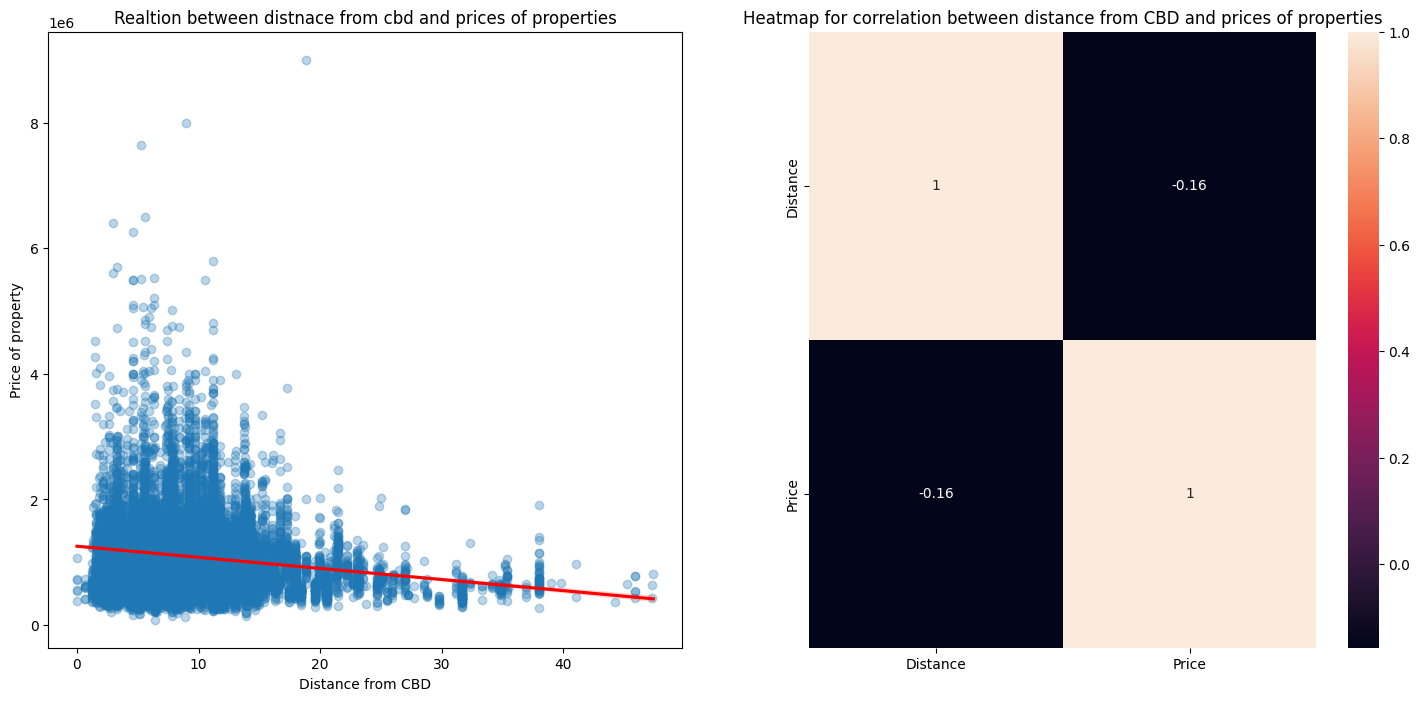

In [233]:
fig,axes=plt.subplots(1,2, figsize=(18,8))
sns.regplot(data=df_melb, x="Distance", y="Price", ax=axes[0],scatter_kws={'alpha':0.3},line_kws={'color': 'red'})
axes[0].set_title("Realtion between distnace from cbd and prices of properties")
axes[0].set_xlabel("Distance from CBD")
axes[0].set_ylabel("Price of property")




sns.heatmap(cbd_corr,annot=True,ax=axes[1])
axes[1].set_title("Heatmap for correlation between distance from CBD and prices of properties")

plt.show()


##### Finding relation between house size and prices
Simillarly we will find relation between the house size, (in this case land size) and prices
We will see a heat map showing correlation, scatter plot and regpllot

          Landsize     Price
Landsize  1.000000  0.038601
Price     0.038601  1.000000


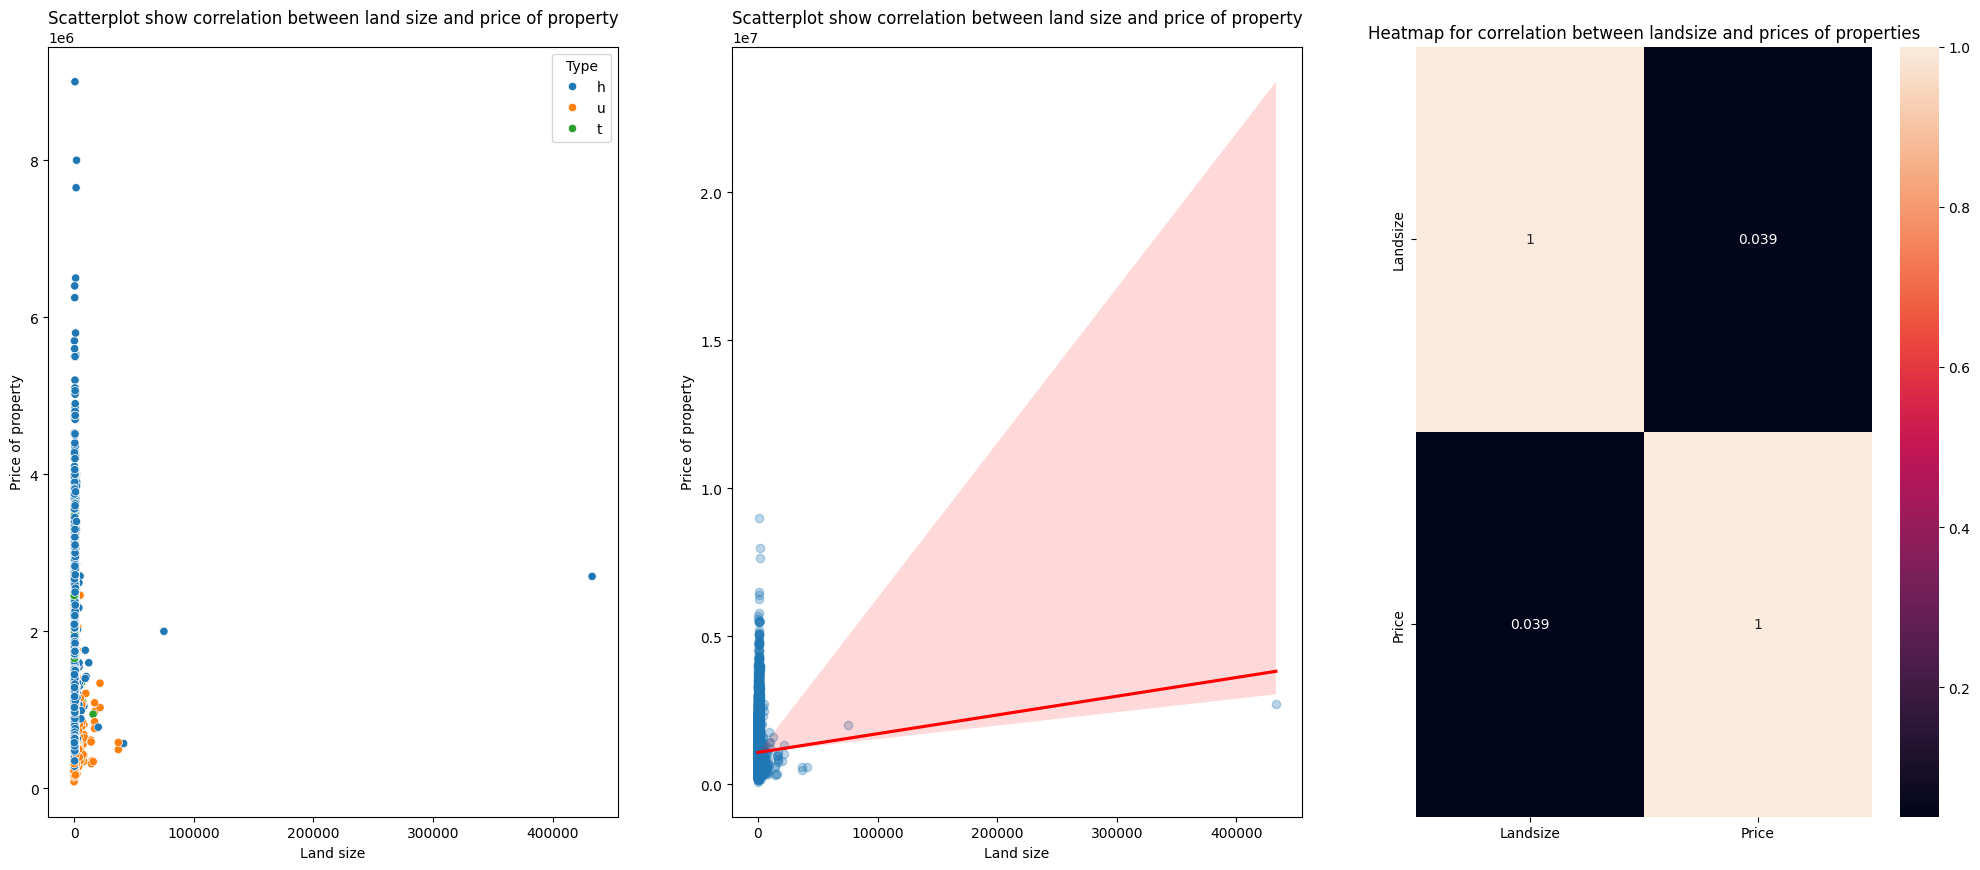

In [276]:
#get correlation matrix
corr_landsize=df_melb[['Landsize','Price']].corr()
print(corr_landsize)

fig,axes=plt.subplots(1,3,figsize=(25,10))

#plot scatterplot
sns.scatterplot(df_melb,x='Landsize',y='Price',hue='Type', ax=axes[0])
axes[0].set_title("Scatterplot show correlation between land size and price of property")
axes[0].set_xlabel("Land size")
axes[0].set_ylabel("Price of property")


#plot regplot
sns.regplot(data=df_melb, x="Landsize", y="Price", ax=axes[1],scatter_kws={'alpha':0.3},line_kws={'color': 'red'})
axes[1].set_title("Scatterplot show correlation between land size and price of property")
axes[1].set_xlabel("Land size")
axes[1].set_ylabel("Price of property")


#plot heatmap
sns.heatmap(corr_landsize,annot=True,ax=axes[2])
axes[2].set_title("Heatmap for correlation between landsize and prices of properties")

plt.show()



We see that here is no correlation between landsize and proce of property as such

Let us see how prices of property varies according to in which year it was sold

Let us see how price of property varies according to in which year it was sold

           YearBuilt     Price
YearBuilt   1.000000 -0.247792
Price      -0.247792  1.000000
           Years Old     Price
Years Old   1.000000  0.248206
Price       0.248206  1.000000


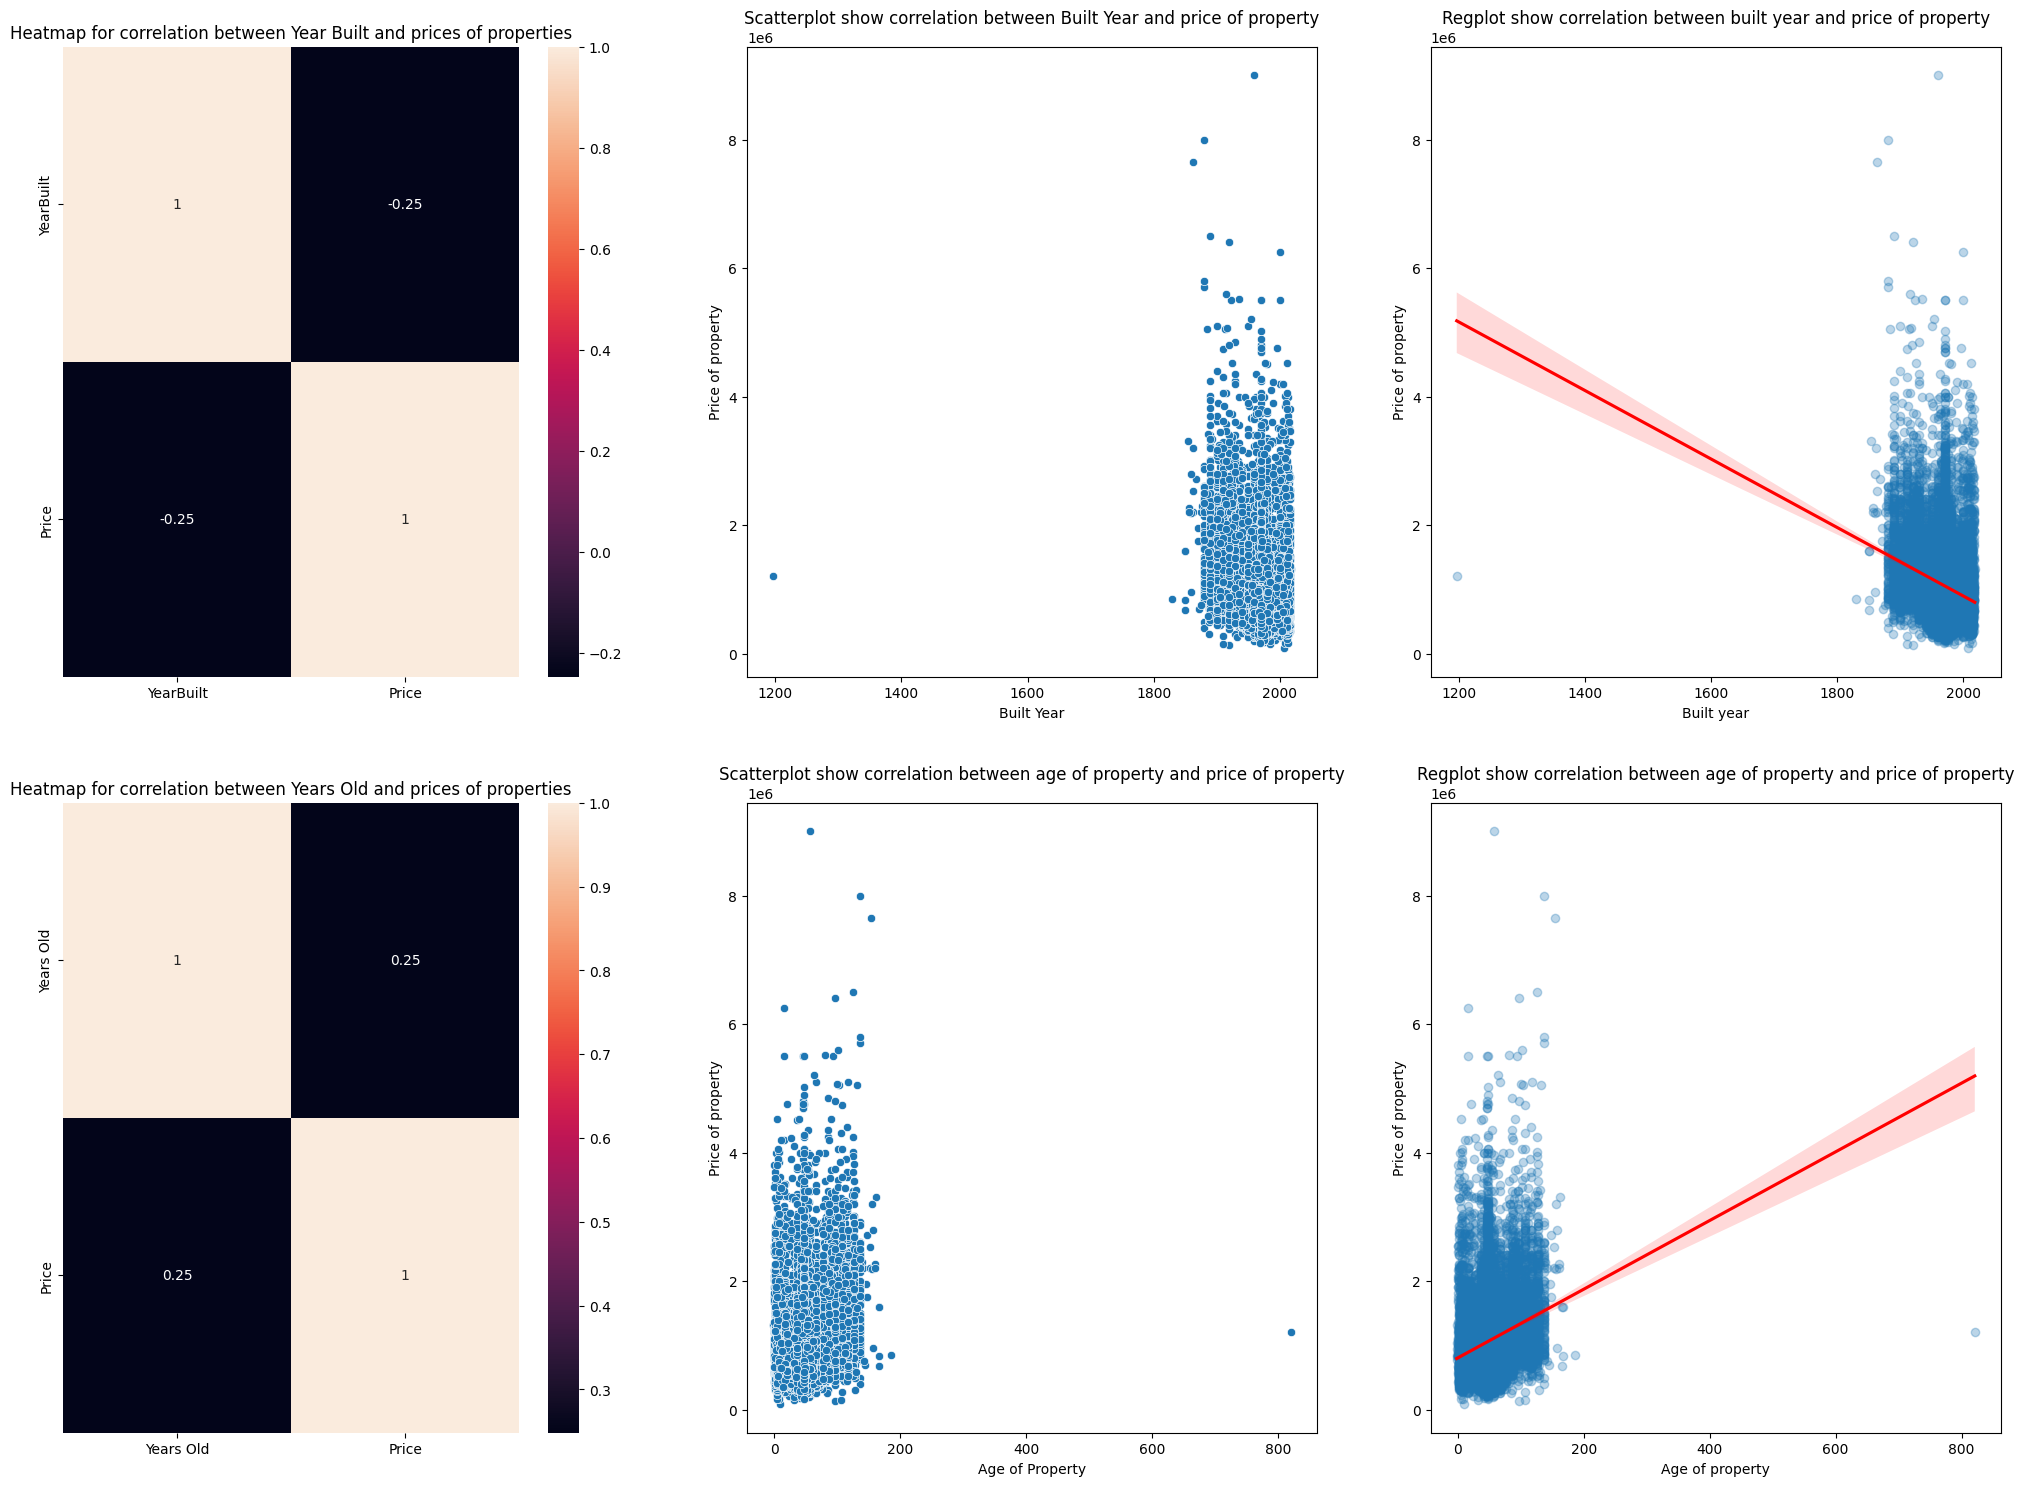

In [292]:
year_built_corr=df_melb[['YearBuilt','Price']].corr()
print(year_built_corr)

years_old_corr=df_melb[['Years Old','Price']].corr()
print(years_old_corr)

fig,axes=plt.subplots(2,3, figsize=(25,18))
axes=axes.flatten()

#plot correlation of year built and price
sns.heatmap(year_built_corr,annot=True,ax=axes[0])
axes[0].set_title("Heatmap for correlation between Year Built and prices of properties")

#plot scatter plot for year built and price
sns.scatterplot(df_melb,x='YearBuilt',y='Price', ax=axes[1])
axes[1].set_title("Scatterplot show correlation between Built Year and price of property")
axes[1].set_xlabel("Built Year")
axes[1].set_ylabel("Price of property")


#regplot for year built and price
sns.regplot(data=df_melb, x="YearBuilt", y="Price", ax=axes[2],scatter_kws={'alpha':0.3},line_kws={'color': 'red'})
axes[2].set_title("Regplot show correlation between built year and price of property")
axes[2].set_xlabel("Built year")
axes[2].set_ylabel("Price of property")


#plot correlation of years old  and price
sns.heatmap(years_old_corr,annot=True,ax=axes[3])
axes[3].set_title("Heatmap for correlation between Years Old and prices of properties")

#plot scatter plot for year built and price
sns.scatterplot(df_melb,x='Years Old',y='Price', ax=axes[4])
axes[4].set_title("Scatterplot show correlation between age of property and price of property")
axes[4].set_xlabel("Age of Property")
axes[4].set_ylabel("Price of property")


#regplot for year built and price
sns.regplot(data=df_melb, x="Years Old", y="Price", ax=axes[5],scatter_kws={'alpha':0.3},line_kws={'color': 'red'})
axes[5].set_title("Regplot show correlation between age of property and price of property")
axes[5].set_xlabel("Age of property")
axes[5].set_ylabel("Price of property")


plt.show()

The analysis explores the relationship between Year Built, Years Old, and Property Price.

1) The heatmaps indicate a weak negative correlation (-0.25) between Year Built and Price, meaning newer properties tend to be more expensive.
2) Conversely, there is a weak positive correlation (0.25) between Years Old and Price, indicating older properties tend to be cheaper, though there are exceptions.
3) The scatterplots show that most properties were built after 1900, with a few extremely old properties (outliers), which may distort trends.
4) The regression plots confirm these weak relationships, with significant price variation at every age — highlighting that factors beyond age, such as location, size, and property type, are also important.
5) Overall, while age influences price, it is not a strong predictor on its own.

##### Let us explore council area

We will analyze things like
1) How many houses are there in each council
2) Top 10 Council Areas with most houses
3) Top 10 council areas with highest mean prices of houses

In [255]:
#let's see number oh houses in all council areas
houses_council=df_melb[['CouncilArea']].groupby(by='CouncilArea').size().reset_index(name='HouseCount')

In [256]:
houses_council.head()


,CouncilArea,HouseCount
0,Banyule,652
1,Bayside,548
2,Boroondara,1281
3,Brimbank,485
4,Cardinia,5


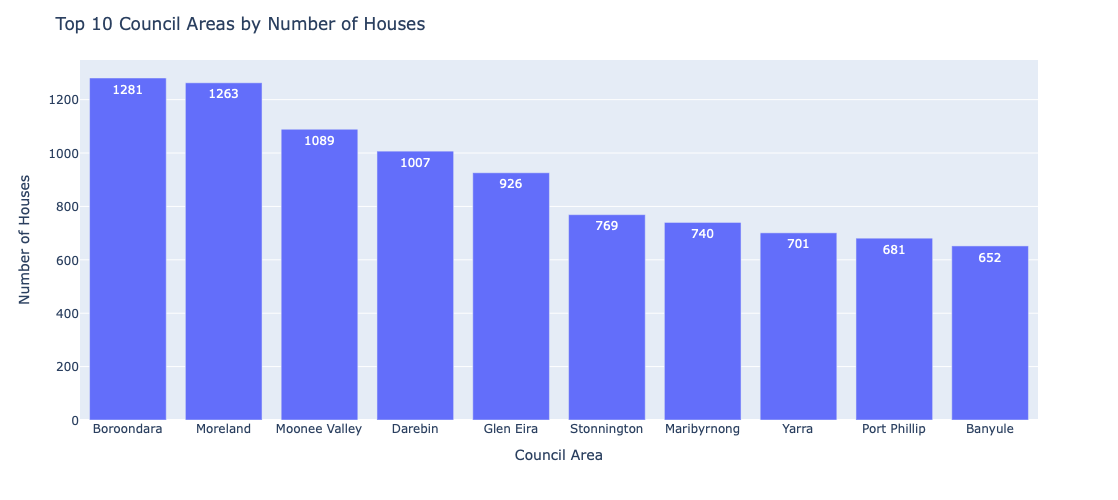

In [295]:
fig=px.bar(data_frame=houses_council.sort_values(by='HouseCount',ascending=False).head(10),x='CouncilArea',y='HouseCount',
          text='HouseCount')

fig.update_traces(texttemplate='%{text}',
                  textposition='auto')

fig.update_layout(
    title="Top 10 Council Areas by Number of Houses",
    xaxis_title="Council Area",
    yaxis_title="Number of Houses",
    height=500,
    width=800
)

Let us determine average prices in each council area 

In [264]:
council_avg_price=df_melb[['CouncilArea','Price']].groupby(by='CouncilArea').mean('Price').reset_index()

In [266]:
council_avg_price.head()

,CouncilArea,Price
0,Banyule,9.582734e+05
1,Bayside,1.659761e+06
2,Boroondara,1.687030e+06
3,Brimbank,6.484605e+05
4,Cardinia,6.157000e+05


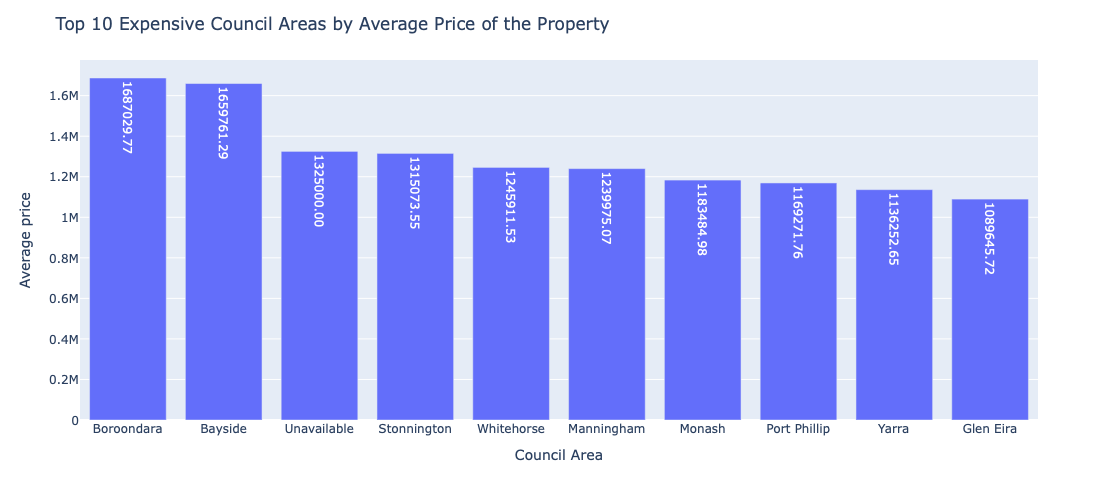

In [278]:
fig=px.bar(data_frame=council_avg_price.sort_values(by='Price',ascending=False).head(10),x='CouncilArea',y='Price',
           text='Price')

fig.update_traces(texttemplate='%{text:0.2f}',
                  textposition='auto')

fig.update_layout(
    title="Top 10 Expensive Council Areas by Average Price of the Property",
    xaxis_title="Council Area",
    yaxis_title="Average price",
    height=500,
    width=800
)

fig.show()



# Part B - Gradient Descent

As given in the question we will only focus on a particular suburb and only one feature Bedroom2

In [302]:
def filter_by_suburb(suburb):
    df=df_melb[df_melb['Suburb']==suburb][['Bedroom2','Price']].reset_index(drop=True)
    return df
    

In [303]:
caufield_df=filter_by_suburb('Caulfield North')

In [304]:
caufield_df.head()

,Bedroom2,Price
0,3.0,1365000.0
1,3.0,1750000.0
2,2.0,580000.0
3,4.0,2005000.0
4,2.0,523000.0


In [319]:
def get_featrues_labels(df):
    X=df['Bedroom2']
    y=df['Price']
    return(X,y)
    

In [320]:
X,y=get_featrues_labels(caufield_df)


In [321]:
X

0     3.0
1     3.0
2     2.0
3     4.0
4     2.0
5     2.0
6     1.0
7     2.0
8     2.0
9     2.0
10    3.0
11    4.0
12    2.0
13    2.0
14    3.0
15    2.0
16    2.0
17    4.0
18    2.0
19    2.0
20    4.0
21    1.0
22    2.0
23    2.0
24    4.0
25    4.0
26    2.0
27    2.0
28    1.0
29    2.0
30    3.0
31    2.0
32    4.0
33    1.0
34    2.0
Name: Bedroom2, dtype: float64

In [322]:
y

0     1365000.0
1     1750000.0
2      580000.0
3     2005000.0
4      523000.0
5      420000.0
6      290000.0
7      608000.0
8      570000.0
9      520500.0
10    1400000.0
11    2830000.0
12     722000.0
13     450000.0
14    1870000.0
15     622000.0
16     536000.0
17    2625000.0
18     570000.0
19     550000.0
20    2170000.0
21     305000.0
22     550000.0
23     655000.0
24    1300000.0
25    1700000.0
26     575000.0
27     742500.0
28     350000.0
29     665000.0
30    1520000.0
31    1417500.0
32    1925000.0
33     361000.0
34     610000.0
Name: Price, dtype: float64

### Gradient Descent 
Below code shows the working of a gradient descent, we start with values of m and c as zero and update them as the iterations proceeds

In [330]:
lr=0.01
def gradient_descent(lr):
    m,c=0,0
    
    
    best_m,best_c=None,None
    
    cost_history=[]
    previous_cost=None
    
    iterations=1000
    for i in range(iterations):
        predictions=m*X_train+c
        error=predictions - y_train
        cost=(error ** 2).mean()
        print(f"iteration {i+1}, cost :{cost}")
        if previous_cost is not None and (cost<previous_cost):
            best_m,best_c=m,c
    
        
    
        #update params
        m_grad = (2/len(X_train)) * sum(error * X_train)
        c_grad = (2/len(X_train)) * sum(error)
    
        m=m-lr*m_grad
        c=c-lr*c_grad
    
        cost_history.append(cost)
        previous_cost=cost

    return(best_m,best_c,cost_history)




    

    
    

In [331]:
best_m,best_c,cost_history=gradient_descent(lr)

iteration 1, cost :2016631312500.0
iteration 2, cost :1436876981964.5833
iteration 3, cost :1038352487943.1377
iteration 4, cost :764373882201.1967
iteration 5, cost :575986619757.0826
iteration 6, cost :446420218649.2363
iteration 7, cost :357277371670.95166
iteration 8, cost :295915014301.0876
iteration 9, cost :253644532974.1193
iteration 10, cost :224494905862.13095
iteration 11, cost :204362704122.3253
iteration 12, cost :190427952757.55557
iteration 13, cost :180752696457.4252
iteration 14, cost :174005124600.27475
iteration 15, cost :169269983464.38217
iteration 16, cost :165918287039.29233
iteration 17, cost :163517779230.18738
iteration 18, cost :161771401378.25644
iteration 19, cost :160475005693.06137
iteration 20, cost :159488294928.397
iteration 21, cost :158714851443.83646
iteration 22, cost :158088412705.95248
iteration 23, cost :157563439489.8354
iteration 24, cost :157108634125.24307
iteration 25, cost :156702486082.82446
iteration 26, cost :156330210796.13516
iteratio

Text(0.5, 1.0, 'Cost over iteartions')

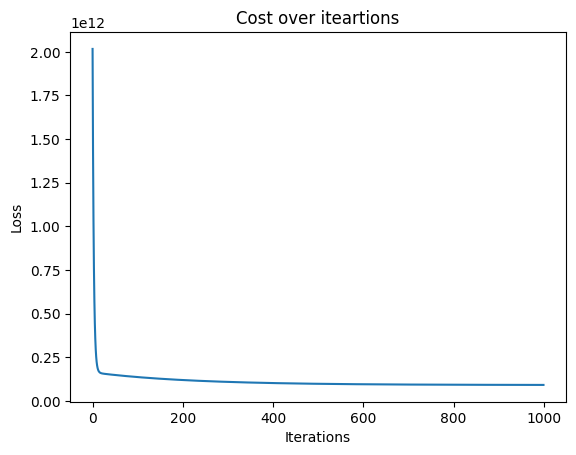

In [332]:
#plot costline
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("Cost over iteartions")

In [333]:
print(f"best m and c is {best_m},{best_c}")

best m and c is 671127.6401256318,-523698.87672052183


In [335]:
#plot data and regression line
def plot(best_m,best_c):
    plt.scatter(X, y, color='blue', label='Actual Data')
    plt.plot(X, best_m*X + best_c, color='red', label='Regression Line')
    plt.title('Gradient Descent for Price Prediction')
    plt.xlabel('Bedrooms')
    plt.ylabel('Price')
    plt.legend()
    plt.show()

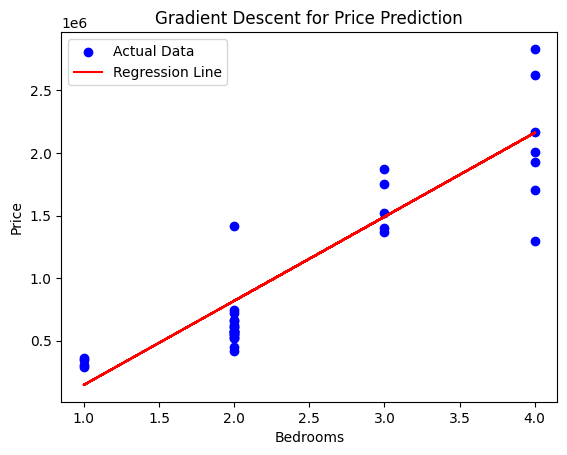

In [337]:
plot(best_m,best_c)

below section, we will determine  how learning rate affects m and c